# Bangladesh Rice Price Analysis — Coarse Rice (BDT/kg)

Hi, I am Md. Emon Rana, a final-year CSE student at Southeast University.
This notebook looks at the price of **coarse rice** — the rice most families in Bangladesh buy every day.

**My question was simple:** how much has the price of coarse rice gone up, when does it go up most, and can we guess next month's price?

**Data (real, not made up):** WFP Food Prices for Bangladesh, from Humanitarian Data Exchange (HDX).
- Link: https://data.humdata.org/dataset/wfp-food-prices-for-bangladesh
- The data was collected by FAO GIEWS / FPMA and Bangladesh Department of Agricultural Marketing (DAM).
- Licence: CC BY-IGO.
- File used here: `data/wfp_food_prices_bgd.csv` (34,490 rows, all foods, Jul 1998 – Sep 2026).

**What I do in this notebook:**
1. Load the data and keep only coarse rice, retail price, BDT per kg.
2. Make one monthly price for the whole country (mean of all markets that reported that month).
3. Look at the trend, yearly change, seasonal pattern, and how jumpy the price is.
4. Test 3 simple ways to guess next month's price — and report the honest error.

Run the cells one by one from the top (Kernel → Restart & Run All also works).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({"font.size": 10, "figure.dpi": 120})
os.makedirs("outputs", exist_ok=True)

## 1. Load the data

The file has many foods — wheat, lentils, oil, onion, and more. First I just load it and look at it.

In [2]:
raw = pd.read_csv("data/wfp_food_prices_bgd.csv", parse_dates=["date"])
print("Rows:", len(raw))
print("Date range:", raw["date"].min().date(), "to", raw["date"].max().date())
print(raw.columns.tolist())
raw.head()

Rows: 34490
Date range: 1998-07-15 to 2026-09-15
['date', 'admin1', 'admin2', 'market', 'market_id', 'latitude', 'longitude', 'category', 'commodity', 'commodity_id', 'unit', 'priceflag', 'pricetype', 'currency', 'price', 'usdprice']


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,1998-07-15,Dhaka,Dhaka,Dhaka,2574,23.81,90.41,cereals and tubers,"Rice (coarse, BR-8/ 11/, Guti Sharna)",588,100 KG,actual,Wholesale,BDT,1261.40,18.41
1,1998-07-15,Dhaka,Dhaka,Dhaka,2574,23.81,90.41,cereals and tubers,Wheat,84,100 KG,actual,Wholesale,BDT,1055.60,15.41
2,1998-08-15,Dhaka,Dhaka,Dhaka,2574,23.81,90.41,cereals and tubers,"Rice (coarse, BR-8/ 11/, Guti Sharna)",588,100 KG,actual,Wholesale,BDT,1288.75,18.81
3,1998-08-15,Dhaka,Dhaka,Dhaka,2574,23.81,90.41,cereals and tubers,Wheat,84,100 KG,actual,Wholesale,BDT,1060.00,15.47
4,1998-09-15,Dhaka,Dhaka,Dhaka,2574,23.81,90.41,cereals and tubers,"Rice (coarse, BR-8/ 11/, Guti Sharna)",588,100 KG,actual,Wholesale,BDT,1415.50,20.66


## 2. Keep only coarse rice (retail, BDT/kg) and make a monthly series

I keep only `Rice (coarse)`, retail price, unit KG, currency BDT.
Then I take the mean price of all markets in each month — that is my one national monthly price.

One honest point: the number of markets that report changes over time. In 2004 only 1 market reported most months, in recent years it is 27–65 markets. So the early years are less solid than the recent years. I say this clearly in the limitations at the end.

In [3]:
rice = raw[
    (raw["commodity"] == "Rice (coarse)")
    & (raw["pricetype"] == "Retail")
    & (raw["unit"] == "KG")
    & (raw["currency"] == "BDT")
].copy().dropna(subset=["price"])

print("Rice (coarse) rows:", len(rice))
print("Markets:", rice["market"].nunique(), "| Divisions:", rice["admin1"].nunique())
print("Date range:", rice["date"].min().date(), "to", rice["date"].max().date())

# Raw dates are the 15th of the month, so I move them to the 1st first.
rice["month_start"] = rice["date"].dt.to_period("M").dt.to_timestamp()
monthly = (
    rice.groupby("month_start")["price"]
    .agg(["mean", "count", "min", "max"])
    .rename(columns={"mean": "price", "count": "n_markets"})
    .reset_index().rename(columns={"month_start": "date"})
    .sort_values("date")
)
monthly["date"] = pd.to_datetime(monthly["date"])
monthly = monthly.set_index("date").asfreq("MS")
print("Missing months filled by interpolation:", int(monthly["price"].isna().sum()))
monthly["price"] = monthly["price"].interpolate(limit_direction="both")
monthly["year"] = monthly.index.year
monthly["month"] = monthly.index.month
monthly["pct_change"] = monthly["price"].pct_change() * 100
monthly["yoy"] = monthly["price"].pct_change(12) * 100
monthly["roll12"] = monthly["price"].rolling(12).mean()
monthly.to_csv("data/rice_coarse_monthly.csv")
print("Monthly series:", len(monthly), "months,",
      monthly.index.min().date(), "to", monthly.index.max().date())
monthly.head()

Rice (coarse) rows: 3695
Markets: 86 | Divisions: 8
Date range: 2004-01-15 to 2026-07-15
Missing months filled by interpolation: 4
Monthly series: 271 months, 2004-01-01 to 2026-07-01


,price,n_markets,min,max,year,month,pct_change,yoy,roll12
date,,,,,,,,,
2004-01-01,14.0,1.0,14.0,14.0,2004,1,NaN,NaN,NaN
2004-02-01,14.0,1.0,14.0,14.0,2004,2,0.0,NaN,NaN
2004-03-01,14.0,1.0,14.0,14.0,2004,3,0.0,NaN,NaN
2004-04-01,14.0,1.0,14.0,14.0,2004,4,0.0,NaN,NaN
2004-05-01,14.0,1.0,14.0,14.0,2004,5,0.0,NaN,NaN


## 3. Key numbers

Mean, median, lowest month, highest month — the short answer first.

In [4]:
price = monthly["price"]
print(f"Mean price:    {price.mean():.2f} BDT/kg")
print(f"Median price:  {price.median():.2f} BDT/kg")
print(f"Lowest month:  {price.min():.2f} in {price.idxmin().date()}")
print(f"Highest month: {price.max():.2f} in {price.idxmax().date()}")
print(f"First month ({price.index[0].date()}): {price.iloc[0]:.2f} BDT/kg")
print(f"Last month  ({price.index[-1].date()}): {price.iloc[-1]:.2f} BDT/kg")
print(f"Total change, first to last month: {(price.iloc[-1]/price.iloc[0]-1)*100:+.1f}%")
print(f"Mean month-on-month change: {monthly['pct_change'].mean():+.2f}%")
print(f"Mean year-on-year change: {monthly['yoy'].mean():+.2f}%")
print(f"Year-on-year change, last month: {monthly['yoy'].iloc[-1]:+.2f}%")

Mean price:    32.86 BDT/kg
Median price:  31.60 BDT/kg
Lowest month:  14.00 in 2004-01-01
Highest month: 53.49 in 2025-07-01
First month (2004-01-01): 14.00 BDT/kg
Last month  (2026-07-01): 49.31 BDT/kg
Total change, first to last month: +252.2%
Mean month-on-month change: +0.65%
Mean year-on-year change: +8.21%
Year-on-year change, last month: -7.82%


## 4. Price trend over time

The green line is the monthly price, the red line is the 12-month rolling mean (it smooths out the ups and downs so the long trend is easy to see).

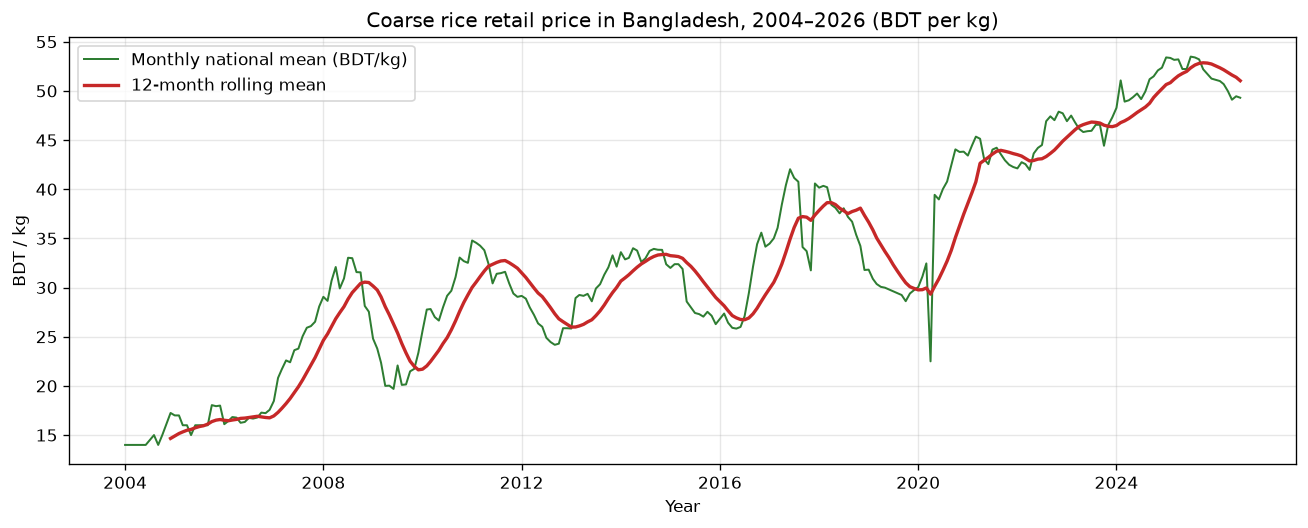

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["price"], color="#2E7D32", lw=1.2,
        label="Monthly national mean (BDT/kg)")
ax.plot(monthly.index, monthly["roll12"], color="#C62828", lw=2,
        label="12-month rolling mean")
ax.set_title("Coarse rice retail price in Bangladesh, 2004–2026 (BDT per kg)")
ax.set_xlabel("Year"); ax.set_ylabel("BDT / kg")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/01_price_trend.png")
plt.show()

## 5. Seasonal pattern — is rice cheaper in some months?

I take the mean price of each calendar month (all Januaries together, all Februaries together, and so on).

Jan    32.57
Feb    33.08
Mar    33.01
Apr    32.41
May    32.68
Jun    32.73
Jul    33.23
Aug    32.79
Sep    32.73
Oct    32.95
Nov    32.97
Dec    33.23
Name: price, dtype: float64
Cheapest month on average: Apr (32.41)
Dearest month on average: Jul (33.23)
Gap: 0.82 BDT/kg


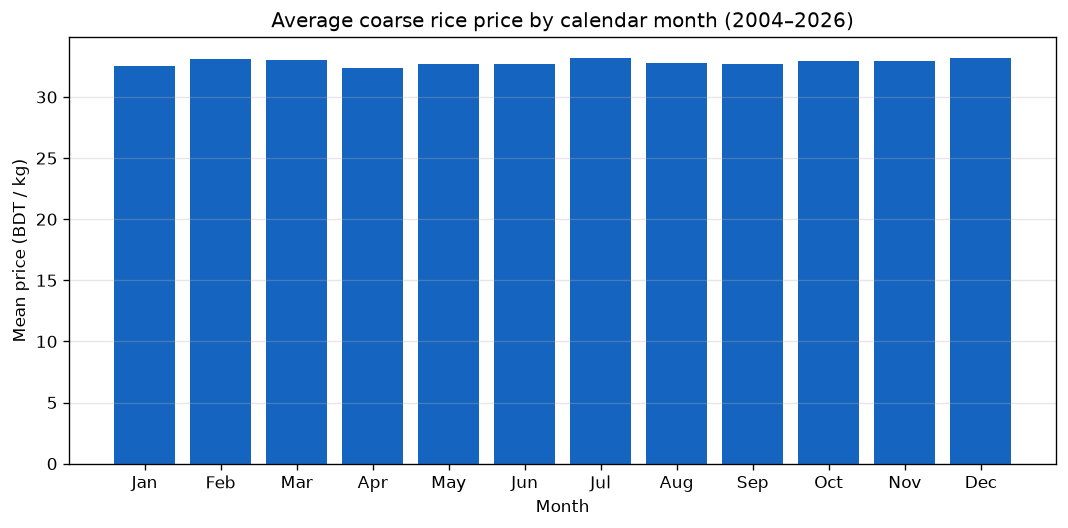

In [6]:
seasonal = monthly.groupby("month")["price"].mean()
seasonal.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                  "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(seasonal.round(2))
print("Cheapest month on average:", seasonal.idxmin(), f"({seasonal.min():.2f})")
print("Dearest month on average:", seasonal.idxmax(), f"({seasonal.max():.2f})")
print("Gap:", round(seasonal.max() - seasonal.min(), 2), "BDT/kg")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(seasonal.index, seasonal.values, color="#1565C0")
ax.set_title("Average coarse rice price by calendar month (2004–2026)")
ax.set_xlabel("Month"); ax.set_ylabel("Mean price (BDT / kg)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/02_monthly_average.png")
plt.show()

## 6. Yearly comparison

Mean price of each year, so we can see the big jumps — like 2007–2008, when the price jumped a lot in one year.

2004:  14.66 BDT/kg   YoY   —  
2005:  16.58 BDT/kg   YoY +13.1%
2006:  16.75 BDT/kg   YoY +1.0%
2007:  23.75 BDT/kg   YoY +41.8%
2008:  30.51 BDT/kg   YoY +28.5%
2009:  21.63 BDT/kg   YoY -29.1%
2010:  29.25 BDT/kg   YoY +35.2%
2011:  31.97 BDT/kg   YoY +9.3%
2012:  26.26 BDT/kg   YoY -17.8%
2013:  30.01 BDT/kg   YoY +14.3%
2014:  33.38 BDT/kg   YoY +11.2%
2015:  29.00 BDT/kg   YoY -13.1%
2016:  29.27 BDT/kg   YoY +0.9%
2017:  37.38 BDT/kg   YoY +27.7%
2018:  37.35 BDT/kg   YoY -0.1%
2019:  29.92 BDT/kg   YoY -19.9%
2020:  37.45 BDT/kg   YoY +25.2%
2021:  43.63 BDT/kg   YoY +16.5%
2022:  44.89 BDT/kg   YoY +2.9%
2023:  46.37 BDT/kg   YoY +3.3%
2024:  50.22 BDT/kg   YoY +8.3%
2025:  52.74 BDT/kg   YoY +5.0%
2026:  50.10 BDT/kg   YoY -5.0%
Cheapest year: 2004 (14.66)
Dearest year: 2025 (52.74)


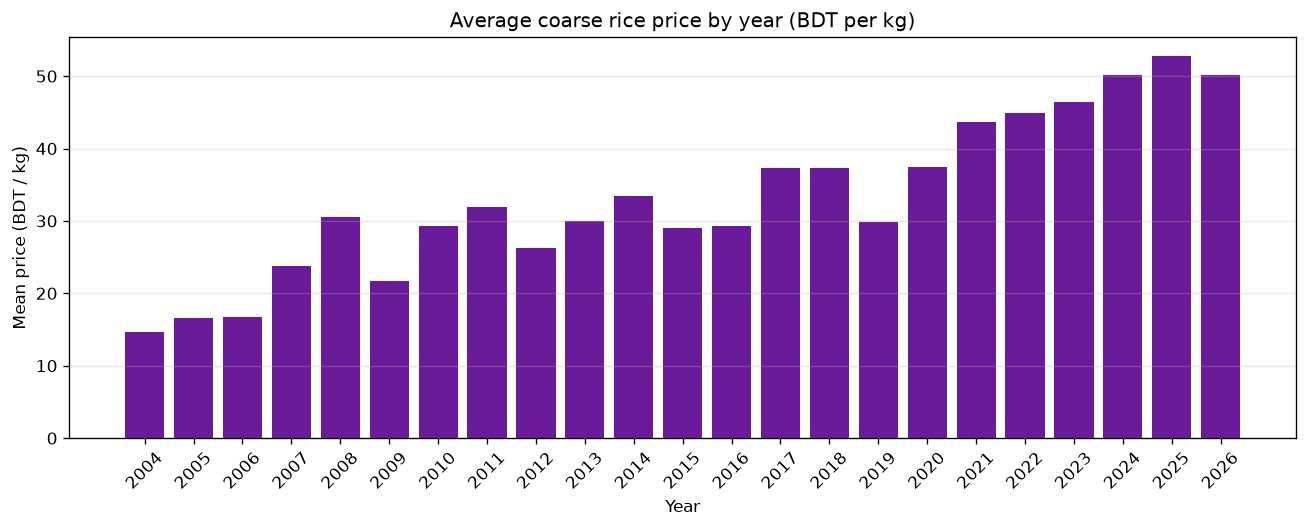

In [7]:
yearly = monthly.groupby("year")["price"].mean()
change = yearly.pct_change() * 100
for y in yearly.index:
    ch = f"{change[y]:+.1f}%" if pd.notna(change[y]) else "  —  "
    print(f"{y}: {yearly[y]:6.2f} BDT/kg   YoY {ch}")
print("Cheapest year:", yearly.idxmin(), f"({yearly.min():.2f})")
print("Dearest year:", yearly.idxmax(), f"({yearly.max():.2f})")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(yearly.index.astype(str), yearly.values, color="#6A1B9A")
ax.set_title("Average coarse rice price by year (BDT per kg)")
ax.set_xlabel("Year"); ax.set_ylabel("Mean price (BDT / kg)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/03_yearly_comparison.png")
plt.show()

## 7. Distribution and volatility — how jumpy is the price?

First, a histogram: most months sit in which price range?
Then the month-on-month % change: big jumps up or down show up as tall spikes.

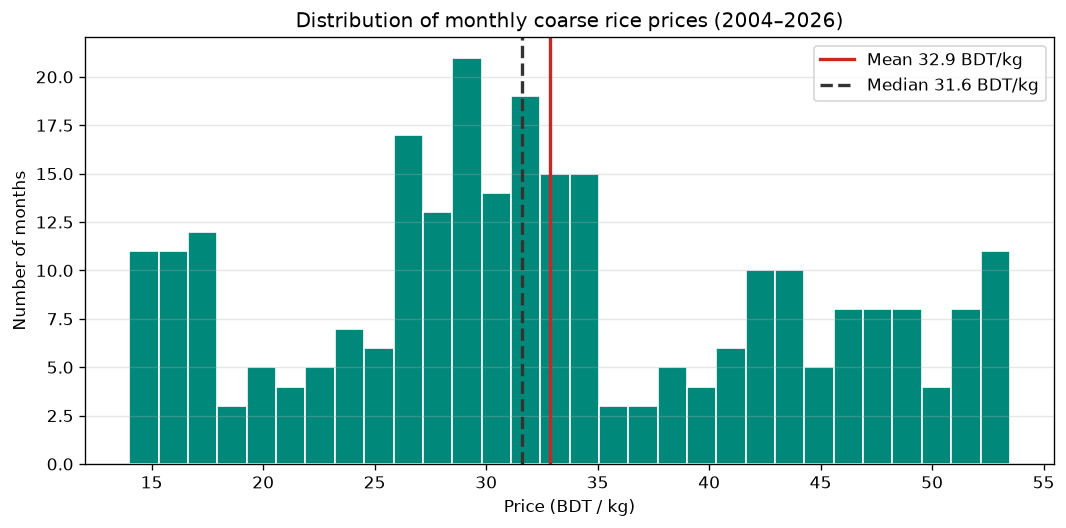

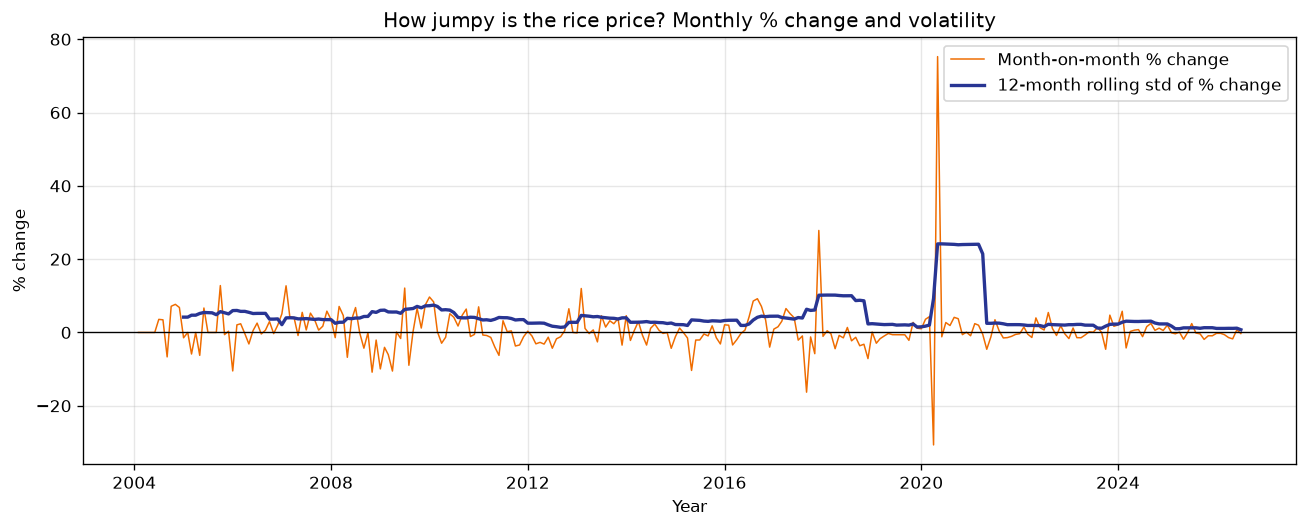

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(price.values, bins=30, color="#00897B", edgecolor="white")
ax.axvline(price.mean(), color="#C62828", lw=2, label=f"Mean {price.mean():.1f} BDT/kg")
ax.axvline(price.median(), color="#333333", lw=2, ls="--",
           label=f"Median {price.median():.1f} BDT/kg")
ax.set_title("Distribution of monthly coarse rice prices (2004–2026)")
ax.set_xlabel("Price (BDT / kg)"); ax.set_ylabel("Number of months")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/04_price_distribution.png")
plt.show()

monthly["roll_vol"] = monthly["pct_change"].rolling(12).std()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["pct_change"], color="#EF6C00", lw=0.9,
        label="Month-on-month % change")
ax.plot(monthly.index, monthly["roll_vol"], color="#283593", lw=2,
        label="12-month rolling std of % change")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("How jumpy is the rice price? Monthly % change and volatility")
ax.set_xlabel("Year"); ax.set_ylabel("% change")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/05_volatility.png")
plt.show()

## 8. Price by division

Which division pays most for coarse rice on average? This is only descriptive — different divisions reported in different years, so it is not a fair like-for-like comparison. I keep it because it is still interesting to look at.

             mean  count
admin1                  
Sylhet      38.77    317
Rajshahi    40.14    501
Barisal     41.59    377
Khulna      42.54    682
Chittagong  42.67    584
Dhaka       43.76    778
Rangpur     45.39    281
Mymensingh  46.55    175


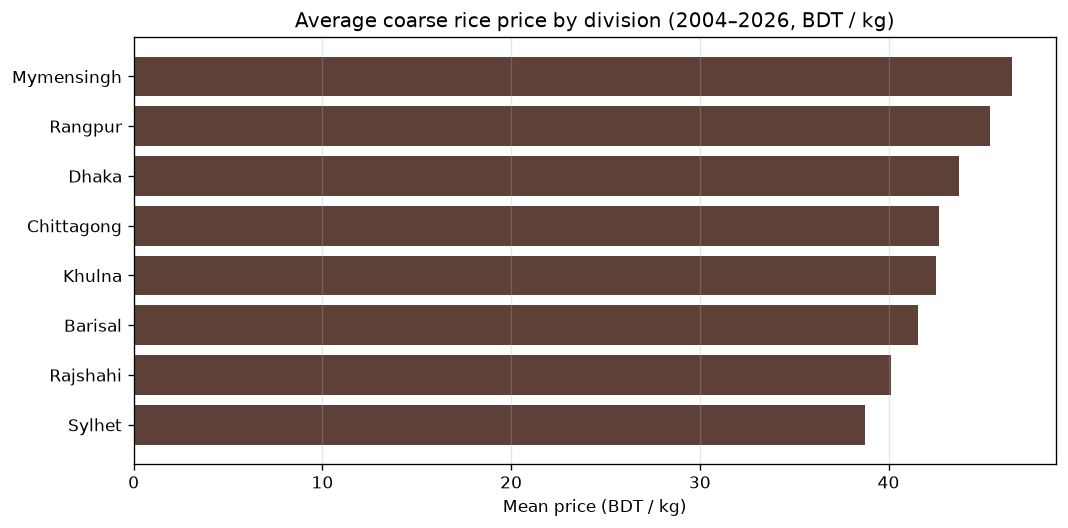

In [9]:
division = rice.groupby("admin1")["price"].agg(["mean", "count"]).sort_values("mean")
print(division.round(2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(division.index, division["mean"].values, color="#5D4037")
ax.set_title("Average coarse rice price by division (2004–2026, BDT / kg)")
ax.set_xlabel("Mean price (BDT / kg)")
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/07_division_comparison.png")
plt.show()

## 9. Can we guess next month's price? (forecast test)

I test on the **last 12 months only** (Aug 2025 – Jul 2026) and train on everything before that. Three simple ways:

1. **Seasonal naive** — guess the price of the same month last year.
2. **Linear trend** — fit a straight line on time and extend it.
3. **Random Forest** — learn from the price 1, 3, 6 and 12 months ago, the month, and time.

I report MAE (mean absolute error) and RMSE for all three. No model is hidden, and a 12-month test is short — so this is a test, not a promise about next month.

Test period: 2025-08-01 to 2026-07-01
Test mean price: 51.04 BDT/kg
Seasonal naive: MAE 2.34 BDT/kg, RMSE 2.58 BDT/kg
Linear trend:   MAE 2.30 BDT/kg, RMSE 2.88 BDT/kg
Random Forest:  MAE 1.47 BDT/kg, RMSE 1.68 BDT/kg


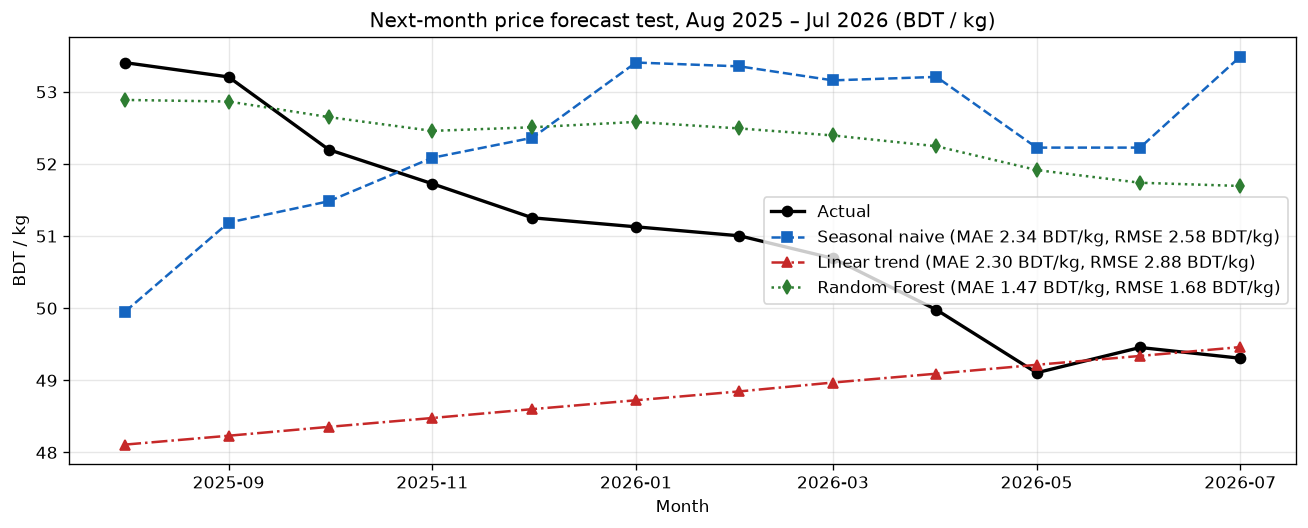

In [10]:
df = monthly[["price"]].copy()
df["lag1"] = df["price"].shift(1)
df["lag3"] = df["price"].shift(3)
df["lag6"] = df["price"].shift(6)
df["lag12"] = df["price"].shift(12)
df["month"] = df.index.month
df["t"] = np.arange(len(df))
df = df.dropna()

train, test = df.iloc[:-12], df.iloc[-12:]
feats = ["lag1", "lag3", "lag6", "lag12", "month", "t"]

pred_naive = test["lag12"].values
lin = LinearRegression().fit(train[["t"]], train["price"])
pred_lin = lin.predict(test[["t"]])
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(train[feats], train["price"])
pred_rf = rf.predict(test[feats])

def scores(a, p):
    return f"MAE {mean_absolute_error(a, p):.2f} BDT/kg, RMSE {np.sqrt(mean_squared_error(a, p)):.2f} BDT/kg"

print("Test period:", test.index.min().date(), "to", test.index.max().date())
print("Test mean price:", round(test["price"].mean(), 2), "BDT/kg")
print("Seasonal naive:", scores(test["price"], pred_naive))
print("Linear trend:  ", scores(test["price"], pred_lin))
print("Random Forest: ", scores(test["price"], pred_rf))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(test.index, test["price"], "o-", color="black", lw=2, label="Actual")
ax.plot(test.index, pred_naive, "s--", color="#1565C0",
        label=f"Seasonal naive ({scores(test['price'], pred_naive)})")
ax.plot(test.index, pred_lin, "^-.", color="#C62828",
        label=f"Linear trend ({scores(test['price'], pred_lin)})")
ax.plot(test.index, pred_rf, "d:", color="#2E7D32",
        label=f"Random Forest ({scores(test['price'], pred_rf)})")
ax.set_title("Next-month price forecast test, Aug 2025 – Jul 2026 (BDT / kg)")
ax.set_xlabel("Month"); ax.set_ylabel("BDT / kg")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("outputs/06_forecast_vs_actual.png")
plt.show()

## 10. What I learned, and the limits (honest part)

**What I found:**
- Coarse rice went from 14.00 BDT/kg (Jan 2004) to 49.31 BDT/kg (Jul 2026) — a rise of about +252% over 22 years. But remember, these are nominal taka, not adjusted for inflation, so part of the rise is just general inflation.
- The dearest year on average was 2025 (52.74 BDT/kg) and the dearest single month was Jul 2025 (53.49 BDT/kg).
- The price fell in the last year of the data: year-on-year change in Jul 2026 was −7.82%.
- There is almost no seasonal pattern — the gap between the cheapest month (Apr, 32.41) and the dearest month (Jul, 33.23) is only 0.82 BDT/kg on average over the whole period.
- In the 12-month forecast test, Random Forest had the smallest error (MAE 1.47 BDT/kg), better than seasonal naive (2.34) and linear trend (2.30). Still, 12 months is a short test.

**Limits — please read these:**
- The monthly price is a mean of the markets that reported that month. In 2004 only 1 market reported most months; recently it is 27–65 markets. Early years are weaker.
- 4 months had no data at all and were filled by interpolation (a straight line between the months around them).
- Only coarse rice, retail, BDT/kg. Fine/medium rice, wholesale and paddy prices are in the raw file but not used here.
- Prices are nominal BDT, not inflation-adjusted.
- The forecast test is only 12 months long. Do not use it to bet on next month's price.
- WFP/HDX data can be revised later — re-download the file for the newest version.

**Files:** `data/wfp_food_prices_bgd.csv` (raw), `data/rice_coarse_monthly.csv` (clean monthly series), `outputs/` (7 charts + `results.txt`), `analysis.py` (same work as a script), `README.md`, `REPORT.md`.

Thank you for reading!